In [1]:
%run -i 'clean_script.py'
import openmc
import numpy as np
import math
import pathlib
import copy
import sys

model = openmc.model.Model()

In [2]:
# Material Definition
p = 'wo'

# No materials for this example
m1 = openmc.Material()
m1.add_element('H',1)
m1.set_density('g/cc',1)
model.materials = openmc.Materials([m1])

In [3]:
# Surface Specification
s1 = openmc.ZCylinder(r=100, boundary_type='vacuum')
s2 = openmc.ZPlane(100, boundary_type='vacuum')
s3 = openmc.ZPlane(-100, boundary_type='vacuum')
s4 = openmc.XPlane(20)
s5 = openmc.XPlane(-20)
s6 = openmc.YPlane(20)
s7 = openmc.YPlane(-20)
s8 = openmc.XPlane(10)
s9 = openmc.XPlane(-10)
s10 = openmc.YPlane(10)
s11 = openmc.YPlane(-10)
s12 = openmc.ZCylinder(r=5)
s13 = openmc.YPlane(19.9)
s14 = openmc.ZCylinder(r=10) 

# Universe specification 
c3_group = []
u1_group = []
def u1():
    c3 = openmc.Cell(region=-s4&+s5&-s6&+s7)
    u1 = openmc.Universe(cells=[c3])
    print(f"u1 create cell c3 {c3.id}")
    c3_group.append(c3.id)
    u1_group.append(u1.id)
    return u1

c4_group = []
u2_group = []
def u2():
    # MCNP defined this region like so:
    # c4 = openmc.Cell(region=-s8&+s9&-s10&+s11)
    # and it can do this because it will automatically tesselate
    # this cell as a lattice to cover the entire region it fills.

    # But in OpenMC, we need to explicitly enumerate where the lattice
    # is intended to start and end. So we instead need cell whose region
    # covers the portion of the lattice that we are interested in: 
    c4 = openmc.Cell(region=-s4&+s5&-s6&+s7)
    c4_lat = openmc.RectLattice()
    c4_lat.lower_left=(-30,-30) # We can still tessellate outside the bounds of c4.
    c4_lat.upper_right=(30,30)
    c4_lat.pitch=(20,20)

    # In order to get these partially filled lattices, one needs
    # to specify an outer universe.
    c4_lat.universes = np.tile(u3(),(3,3))
    c4.fill=c4_lat
    
    u2 = openmc.Universe(cells=[c4])
    print(f"u2 create cell c4 {c4.id}")
    c4_group.append(c4.id)
    u2_group.append(u2.id)
    return u2

c5_group = []
c6_group = []
u3_c5_cells = []
u3_c6_cells = []
c5_in_c7_cells = []
c6_in_c7_cells = []
u3_group = []
def u3(add_to_u3=True):
    c5 = openmc.Cell(region=-s12)
    c6 = openmc.Cell(region=+s12)
    u3 = openmc.Universe(cells=[c5,c6])
    print(f"u3 create cell c5 {c5.id} and c6 {c6.id}")
    c5_group.append(c5.id)
    c6_group.append(c6.id)
    u3_group.append(u3.id)
    if add_to_u3:
        u3_c5_cells.append(c5.id)
        u3_c6_cells.append(c6.id)
    else: 
        c5_in_c7_cells.append(c5.id)
        c6_in_c7_cells.append(c6.id)
    return u3

u4_group = []
like_c7_cells = []
c12_group = []
def u4():
    def like_c7(trcl, name="c7"):
        # To replicate the TRCL functionality in MCNP,
        # we have to translate the openmc.Region that defines the cell.
        region = -s14&-s2&+s3
        region = region.translate(trcl)
        
        c7 = openmc.Cell(region=region)
        c7.fill = u3(False)
        
        # We also have to translate openmc.UniverseBase, which is done by
        # defining openmc.Cell.fill and then setting openmc.Cell.translation. 
        c7.translation = trcl 
        print(f"c7 create {c7.id}")
        like_c7_cells.append(c7.id)
        return c7

    c7 = like_c7((-60, 40, 0),"c7")
    c8 = like_c7((-30, 40, 0),"c8")
    c9 = like_c7((0, 40, 0),"c9")
    c10 = like_c7((30, 40, 0),"c10")
    c11 = like_c7((60, 40, 0),"c11")
    c12_region = ~c7.region & ~c8.region & ~c9.region & ~c10.region & ~c11.region
    c12 = openmc.Cell(fill=None,region=c12_region)
    c12_group.append(c12.id)
    u4 = openmc.Universe(cells=[c7,c8,c9,c10,c11,c12])
    print(f"u4 create {[c.id for c in [c7,c8,c9,c10,c11,c12]]}")
    u4_group.append(u4.id)
    return u4

#u1().plot(width=(200,200))
#u2().plot(width=(200,200))
#u3().plot(width=(200,200))
#u4().plot(width=(200,200))

u3 create cell c5 3 and c6 4
c7 create 2
u3 create cell c5 6 and c6 7
c7 create 5
u3 create cell c5 9 and c6 10
c7 create 8
u3 create cell c5 12 and c6 13
c7 create 11
u3 create cell c5 15 and c6 16
c7 create 14
u4 create [2, 5, 8, 11, 14, 17]
u1 create cell c3 19
u3 create cell c5 21 and c6 22
u2 create cell c4 20
u3 create cell c5 23 and c6 24


<Axes: xlabel='x [cm]', ylabel='y [cm]'>

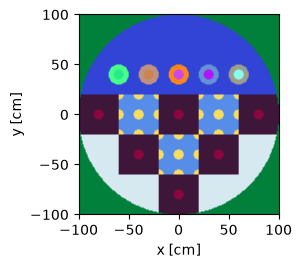

In [4]:
# Identify all cells that are filled with universes and which do not comprise other universes.
# In other words, identify the root cells. These will be part of the root universe.
c1 = openmc.Cell(region=-s1&-s2&+s3&+s13)
c1.fill = u4() 
###################################
c2 = openmc.Cell(region=-s1&-s2&+s3&-s13)

c3_lat = openmc.RectLattice()
c3_lat.lower_left=(-100,-100)
c3_lat.upper_right=(100,20)
c3_lat.pitch=(40,40)

grid = [[3,2,3,2,3],
        [1,3,2,3,1],
        [1,1,3,1,1]]

pattern_map = {1: u1(), 2: u2(), 3: u3()}

u_grid = []
for row in grid:
    universe_row = [pattern_map[u] for u in row]
    u_grid.append(universe_row)

c3_lat.universes = u_grid
c2.fill = c3_lat

c13 = openmc.Cell(region=+s1|+s2|-s3)

###################################

root_universe = openmc.Universe(cells=[c1,c2,c13])
model.geometry = openmc.Geometry(root_universe)
root_universe.plot(width=(200,200), color_by='cell')

To investigate the geometry more thoroughly and get the number of instances of each cell, we can call Geometry.determine_paths() which will 

In [5]:
model.geometry.determine_paths(instances_only=True)
#print(geometry.get_all_cells())

The tally specification for this example involves a f4 tally (volume-averaged fluence) over 30 bins. 

Line 1: 5 6 (5 6 3)
Bins: Cell 5; Cell 6; The union of Cell 5, 6, 3

Line 2: (5<3) (5<(3[-2:2 -2:0 0:0])) 
Bins: Both are identical; 
Line 3: (5<(7 8 9 10 11)) (5<7 8 9 10 11<1) (5<1)

Line 4: ((5 6)<3[0 -1 0] ((5 6)<3[0:0 -1:-1 0:0]) ((5 6)<3[8])

Line 5: (5<(4[0 0 0]3[8]))(5<4[0 0 0]<3[8]) (3<(3[1]3[2]3[4]3[5]3[6]3[10]))

Line 6: (5<u=3)

SD is the segment divisor; this is used 

With the liberty of Python scripting, there are many ways we can go about gathering the cells required for each tally bin specification. 



In [6]:
tallies_group = []

# Line a
f4_a = openmc.Tally()
f4_a.name = "a1:Cell 5"
f4_a.filters = [openmc.CellFilter(c5_group)]
f4_a.scores = ['flux'] 
tallies_group.append(f4_a)

f4_a = openmc.Tally()
f4_a.name = "a2:Cell 6"
f4_a.filters = [openmc.CellFilter(c6_group)]
f4_a.scores = ['flux'] 
tallies_group.append(f4_a)

f4_a = openmc.Tally()
f4_a.name = "a3:Cell 5 + Cell 6 + Cell 3"
f4_a.filters = [openmc.CellFilter(c5_group + c6_group + c3_group)]
f4_a.scores = ['flux'] 
tallies_group.append(f4_a)

# Line b
f4_b = openmc.Tally()
f4_b.name = "b12:Cell 5 of Universe 3"
# Need to find c5 cells that are specifically in u3.
f4_b.filters = [openmc.CellFilter(u3_c5_cells)]
f4_b.scores=['flux']
tallies_group.append(f4_b)

#f4_b = openmc.Tally()
#f4_b.name = "b:Cell 5 of Universe 3[-2:2 -2:0 0:0]"
#f4_b.filters = [openmc.CellFilter(u3_c5_cells)]
#f4_b.scores=['flux']
#tallies_group.append(f4_b)

# Line c
f4_c = openmc.Tally()
f4_c.name = "c123:Cell 5 of Cells[7 8 9 10 11]"
f4_c.filters = [openmc.CellFilter(c5_in_c7_cells)]
f4_c.scores=['flux']
tallies_group.append(f4_c)

# Line d
f4_d = openmc.Tally()
f4_d.name = "d123:Cells 5 and 6 in Lattice[0 -1 0]"
f4_d.filters = [openmc.CellInstanceFilter(
    [(21,a) for a in np.arange(0,9)] + 
    [(22,a) for a in np.arange(0,9)])]
f4_d.scores=['flux']
tallies_group.append(f4_d)

# Line e
f4_e = openmc.Tally()
f4_e.name = "e1:Specific Cell 5 instances"
f4_e.filters = [openmc.CellInstanceFilter(
    [(21,a) for a in np.arange(0,9)] + 
    [(21,13),(21,22)])
               ]
f4_e.scores=['flux']
tallies_group.append(f4_e)

f4_e = openmc.Tally()
f4_e.name = "e2:Single Cell 5 instance"
f4_e.filters = [openmc.CellInstanceFilter(
    [(21,4)])]
f4_e.scores=['flux']
tallies_group.append(f4_e)

f4_e = openmc.Tally()
f4_e.name = "e3: Specific Lattice universe"
f4_e.filters = [openmc.UniverseFilter(u1_group)]
#[openmc.CellInstanceFilter([(19,a) for a in np.arange(0,6)])]
f4_e.scores=['flux']
tallies_group.append(f4_e)

# Line f

f4_f = openmc.Tally()
f4_f.name = "f:Cell 5 in universe 3"
f4_f.filters = [openmc.CellFilter(c5_in_c7_cells + [21] + [23])]
f4_f.scores=['flux']
tallies_group.append(f4_f)

model.tallies = openmc.Tallies(tallies=tallies_group)
for tally in model.tallies:
    print(tally.name,tally.filters)

a1:Cell 5 [CellFilter
	Bins           =	[ 3  6  9 12 15 21 23]
	ID             =	1
]
a2:Cell 6 [CellFilter
	Bins           =	[ 4  7 10 13 16 22 24]
	ID             =	2
]
a3:Cell 5 + Cell 6 + Cell 3 [CellFilter
	Bins           =	[ 3  6  9 12 15 21 23  4  7 10 13 16 22 24 19]
	ID             =	3
]
b12:Cell 5 of Universe 3 [CellFilter
	Bins           =	[21 23]
	ID             =	4
]
c123:Cell 5 of Cells[7 8 9 10 11] [CellFilter
	Bins           =	[ 3  6  9 12 15]
	ID             =	5
]
d123:Cells 5 and 6 in Lattice[0 -1 0] [CellInstanceFilter
	Bins           =	[[21  0]
 [21  1]
 [21  2]
 [21  3]
 [21  4]
 [21  5]
 [21  6]
 [21  7]
 [21  8]
 [22  0]
 [22  1]
 [22  2]
 [22  3]
 [22  4]
 [22  5]
 [22  6]
 [22  7]
 [22  8]]
	ID             =	6
]
e1:Specific Cell 5 instances [CellInstanceFilter
	Bins           =	[[21  0]
 [21  1]
 [21  2]
 [21  3]
 [21  4]
 [21  5]
 [21  6]
 [21  7]
 [21  8]
 [21 13]
 [21 22]]
	ID             =	7
]
e2:Single Cell 5 instance [CellInstanceFilter
	Bins           =	[

f4_b = openmc.Tally()
f4_b.filters = [openmc.UniverseFilter(u4_group)]
f4_b.name = "b:Universe 4"
f4_b.scores=['flux']
tallies_group.append(f4_b)

f4_b = openmc.Tally()
f4_b.filters = [openmc.CellFilter(u4_group)]
f4_b.name = "b:Universe 4"
f4_b.scores=['flux']
tallies_group.append(f4_b)

In [7]:
settings = openmc.Settings()
settings.run_mode='fixed source'

background = openmc.IndependentSource()

source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,0))
source.angle = openmc.stats.Isotropic()
source.particle = 'neutron'
source.energy = openmc.stats.delta_function(1e6) # energy in eV 


# Enable photon transport
#settings.photon_transport = True 

# fluorescence photons and auger electrons enabled
#settings.atomic_relaxation = True 

settings.source = [source]
# settings.source_sampling = 

# History settings
settings.particles = 100
settings.batches = 100

model.settings=settings

In [8]:
model.export_to_xml()

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=1.
  warn(msg, IDWarning)


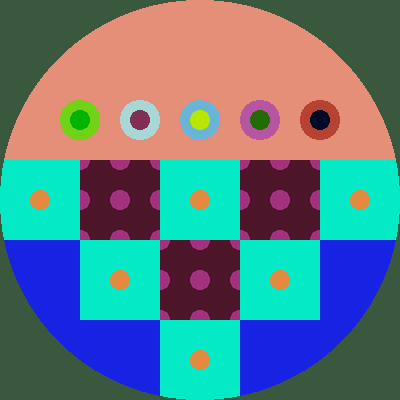

In [9]:
plots = openmc.Plots()
w = 200
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

openmc.plot_inline(plots)

In [10]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [11]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        #print(sp.tallies)
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        #print(df)

        val = df['mean'].sum()
        std = df['std. dev.'].sum()
        
        print(df)
        
        print(f"{tally_name} = {val} +/- {std} particle-cm/source particle\n")
        

   cell nuclide score     mean  std. dev.
0     3   total  flux 1.86e-01   1.53e-02
1     6   total  flux 2.96e-01   1.78e-02
2     9   total  flux 3.94e-01   2.10e-02
3    12   total  flux 2.83e-01   1.49e-02
4    15   total  flux 1.67e-01   1.22e-02
5    21   total  flux 4.67e+00   7.13e-02
6    23   total  flux 8.60e+00   6.98e-02
a1:Cell 5 = 14.593384736137088 +/- 0.22231802147553464 particle-cm/source particle

   cell nuclide score     mean  std. dev.
0     4   total  flux 5.21e-01   2.56e-02
1     7   total  flux 8.25e-01   3.02e-02
2    10   total  flux 1.11e+00   4.49e-02
3    13   total  flux 8.47e-01   3.37e-02
4    16   total  flux 5.04e-01   2.48e-02
5    22   total  flux 1.95e+01   1.73e-01
6    24   total  flux 4.23e+01   2.09e-01
a2:Cell 6 = 65.59833120957305 +/- 0.540795871810516 particle-cm/source particle

    cell nuclide score     mean  std. dev.
0      3   total  flux 1.86e-01   1.53e-02
1      6   total  flux 2.96e-01   1.78e-02
2      9   total  flux 3.94e-01   